# Program 6 — Traffic Sign Detection System

**Aim:** Implement and evaluate a Traffic Sign Detection System using image
processing techniques to identify traffic signs based on their colour from an
input image.

**Method:** Convert to HSV → threshold the red / blue / yellow sign colours →
morphological cleanup → keep contours that are large, round and roughly square.

In [1]:
import cv2
import numpy as np

import matplotlib.pyplot as plt


def show(img, title):
    """Display a BGR or grayscale OpenCV image inside the notebook."""
    plt.figure(figsize=(12, 7))
    if img.ndim == 2:
        plt.imshow(img, cmap="gray")
    else:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


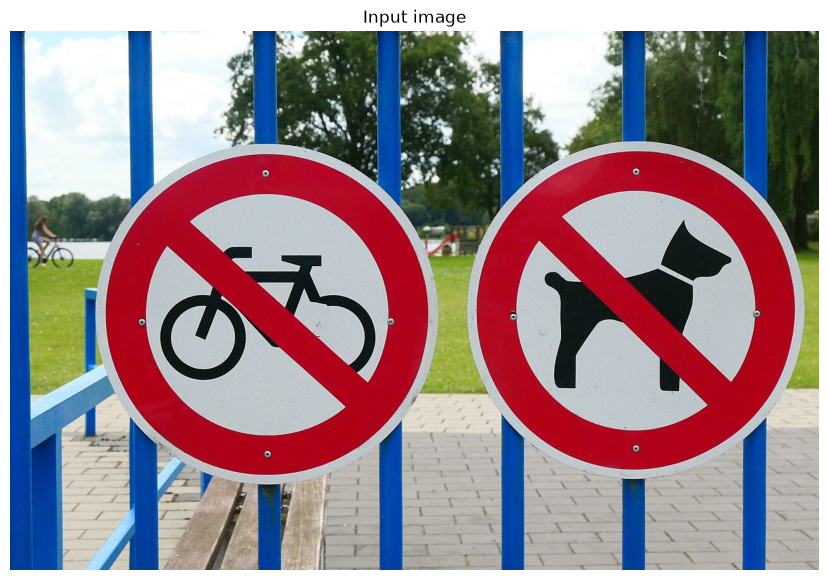

In [2]:
image = cv2.imread("traffic_signs.jpg")
if image is None:
    raise FileNotFoundError("traffic_signs.jpg not found")

hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
show(image, "Input image")

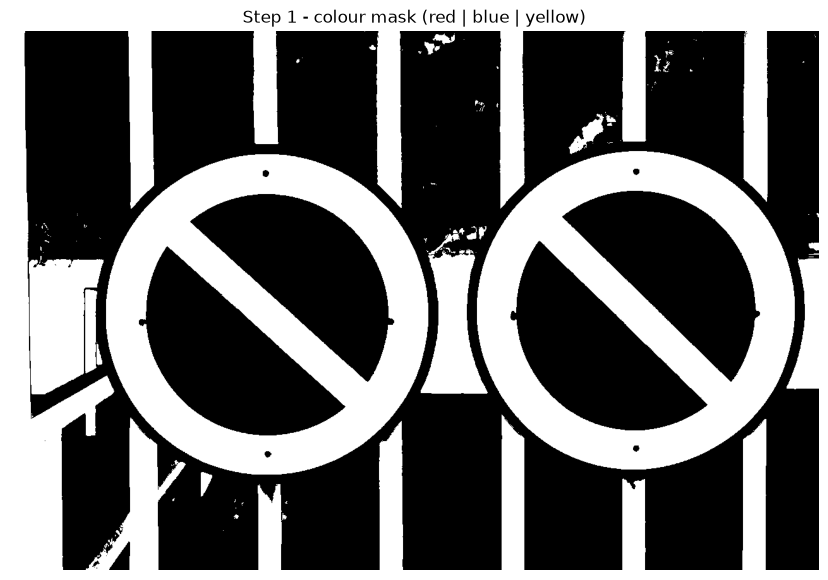

In [3]:
# Step 1 - HSV ranges for the common sign colours
red1 = cv2.inRange(hsv, (0, 80, 80), (10, 255, 255))
red2 = cv2.inRange(hsv, (170, 80, 80), (180, 255, 255))
red = red1 | red2

blue = cv2.inRange(hsv, (90, 80, 70), (130, 255, 255))
yellow = cv2.inRange(hsv, (18, 80, 80), (40, 255, 255))

combined = red | blue | yellow
show(combined, "Step 1 - colour mask (red | blue | yellow)")

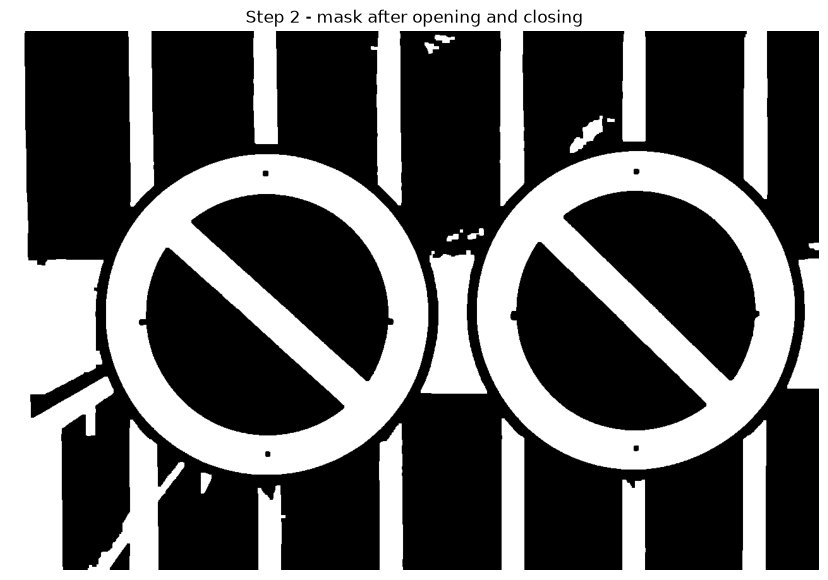

In [4]:
# Step 2 - clean up the mask
kernel = np.ones((5, 5), np.uint8)
combined = cv2.morphologyEx(combined, cv2.MORPH_OPEN, kernel)
combined = cv2.morphologyEx(combined, cv2.MORPH_CLOSE, kernel)

show(combined, "Step 2 - mask after opening and closing")

In [5]:
# Step 3 - keep contours that look like signs
contours, _ = cv2.findContours(combined, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print("Contours found:", len(contours))

count = 0
for cnt in contours:

    area = cv2.contourArea(cnt)
    if area < 500:
        continue

    perimeter = cv2.arcLength(cnt, True)
    if perimeter == 0:
        continue

    # Signs are round or nearly round
    circularity = 4 * np.pi * area / (perimeter * perimeter)
    if circularity < 0.35:
        continue

    x, y, w, h = cv2.boundingRect(cnt)

    # Signs are roughly as wide as they are tall - this rejects
    # poles, railings and other tall thin coloured objects
    aspect_ratio = w / float(h)
    if not 0.6 < aspect_ratio < 1.6:
        continue

    count += 1
    print(f"  sign {count}: area={area:8.0f}  circularity={circularity:.2f}  aspect={aspect_ratio:.2f}")
    cv2.rectangle(image, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.putText(image, "Traffic Sign", (x, y - 8),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 2)

print("\nTraffic signs detected:", count)

Contours found: 26
  sign 1: area=  203072  circularity=0.90  aspect=1.01
  sign 2: area=  198720  circularity=0.90  aspect=1.00

Traffic signs detected: 2


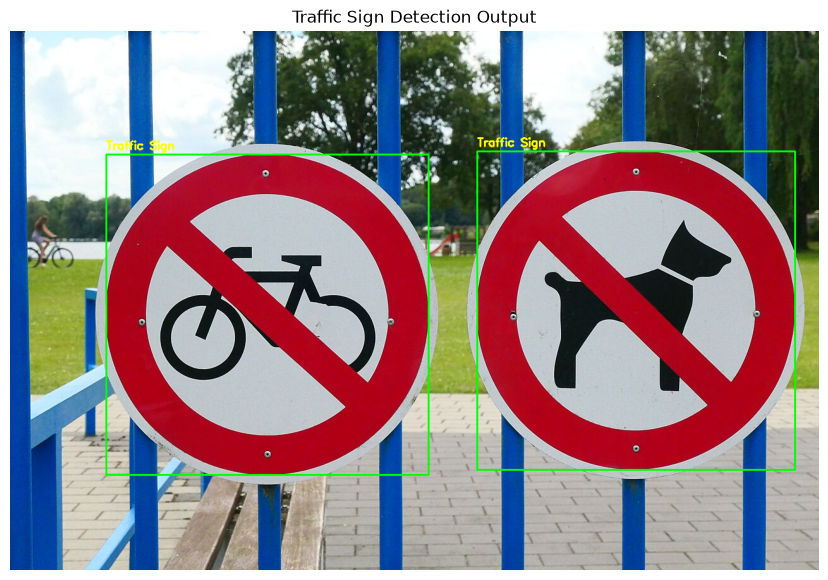

In [6]:
cv2.imwrite("output.jpg", image)
show(image, "Traffic Sign Detection Output")